### 0. Imports

I'll be using a lot of different modules. Here are some of them listed:

[Numpy](https://numpy.org/) \
[Matplotlib](https://matplotlib.org/) \
[Astropy](https://www.astropy.org/) \
[Photutils](https://docs.astropy.org/projects/photutils/en/stable/)

I'd recommend making a [Conda](https://docs.conda.io/projects/conda/en/latest/user-guide/install/index.html) environment, and installing these packages using pip to run the code.

Let me know if you run into any issues!

In [34]:
import numpy as np
import matplotlib.pyplot as plt

from astropy.io import fits
from astropy.time import Time
from astropy.wcs import WCS
from astropy.coordinates import SkyCoord
import astropy.units as u
from astropy.stats import SigmaClip

from photutils.aperture import CircularAperture, CircularAnnulus, aperture_photometry, ApertureStats

### general python imports
import glob
import os
from datetime import datetime


### silence warning, annoying!
import warnings
warnings.filterwarnings("ignore")

print("Imports successful!")
print(datetime.now())

Imports successful!
2026-11-20 13:37:29.091423


### 1. Getting things in order!

In [35]:
### All the w files from every night
# oct16_wfiles = sorted(glob.glob("data/slash/16oct26/oct16_2026_w/w*.fits"))
nov2_wfiles = sorted(glob.glob("data/slash/02nov26/nov02_26_w/w*.fits"))
nov3_wfiles = sorted(glob.glob("data/slash/03nov26/nov03_26_w/w*.fits"))

### also all the regular files
# oct16_files = sorted(glob.glob("data/slash/16oct26/oct16_26/*.fits"))
nov2_files = sorted(glob.glob("data/slash/02nov26/nov02_26/*.fits"))
nov3_files = sorted(glob.glob("data/slash/03nov26/nov03_26/*.fits"))

### Add these lists
wfiles = nov2_wfiles + nov3_wfiles
all_files = nov2_files + nov3_files

In [36]:
### We have to separate the files by target, since two groups shared one night
### I'll use the RA and DEC of our target
### I'll be using astropy a lot, so look up its documentation whenever necessary!

### Our supernova's position
### astropy has a module, see https://docs.astropy.org/en/stable/api/astropy.coordinates.SkyCoord.html
sn26aaiv = SkyCoord("22:37:05.628 +34:24:35.19", unit=(u.hourangle, u.deg))

aaiv_files = []
for f in wfiles:
    h = fits.getheader(f)
    x, y = WCS(h).world_to_pixel(sn26aaiv)
    if (0 <= x < h["NAXIS1"]) and (0 <= y < h["NAXIS2"]):
        aaiv_files.append(f)

print(len(aaiv_files), "files with our SN")
aaiv_files

29 files with our SN


['data/slash/02nov26/nov02_26_w/wnov02_0025.fits',
 'data/slash/02nov26/nov02_26_w/wnov02_0026.fits',
 'data/slash/02nov26/nov02_26_w/wnov02_0027.fits',
 'data/slash/02nov26/nov02_26_w/wnov02_0028.fits',
 'data/slash/02nov26/nov02_26_w/wnov02_0029.fits',
 'data/slash/02nov26/nov02_26_w/wnov02_0030.fits',
 'data/slash/02nov26/nov02_26_w/wnov02_0031.fits',
 'data/slash/02nov26/nov02_26_w/wnov02_0032.fits',
 'data/slash/02nov26/nov02_26_w/wnov02_0033.fits',
 'data/slash/02nov26/nov02_26_w/wnov02_0034.fits',
 'data/slash/02nov26/nov02_26_w/wnov02_0035.fits',
 'data/slash/02nov26/nov02_26_w/wnov02_0036.fits',
 'data/slash/02nov26/nov02_26_w/wnov02_0037.fits',
 'data/slash/02nov26/nov02_26_w/wnov02_0038.fits',
 'data/slash/02nov26/nov02_26_w/wnov02_0039.fits',
 'data/slash/02nov26/nov02_26_w/wnov02_0040.fits',
 'data/slash/02nov26/nov02_26_w/wnov02_0041.fits',
 'data/slash/02nov26/nov02_26_w/wnov02_0042.fits',
 'data/slash/02nov26/nov02_26_w/wnov02_0043.fits',
 'data/slash/02nov26/nov02_26_w

In [37]:
### We have four different filters, so let's split them!
### all our filters
U_files, B_files, V_files, R_files = [], [], [], []

### Going off the filter header
# for f in aaiv_files:
#     filt = fits.getheader(f)["FILTER"]
#     if filt == "Bessell-U":
#         U_files.append(f)
#     ### 4 frames had an empty filter header??? 
#     ### They're in the same sequence as the B ones, so take B
#     elif filt == "Harris-B" or filt == "": 
#         B_files.append(f)
#     elif filt == "Harris-V":
#         V_files.append(f)
#     elif filt == "Harris-R":
#         R_files.append(f)
        
### Going off what the OBJECT header ends in
for f in aaiv_files:
    obj = fits.getheader(f)["OBJECT"]
    if obj.endswith("_U"):
        U_files.append(f)
    elif obj.endswith("_B"):
        B_files.append(f)
    elif obj.endswith("_V"):
        V_files.append(f)
    elif obj.endswith("_R"):
        R_files.append(f)


print("U:", len(U_files), " B:", len(B_files), " V:", len(V_files), " R:", len(R_files))


U: 6  B: 7  V: 6  R: 10


In [38]:
U_files

['data/slash/02nov26/nov02_26_w/wnov02_0032.fits',
 'data/slash/02nov26/nov02_26_w/wnov02_0033.fits',
 'data/slash/02nov26/nov02_26_w/wnov02_0034.fits',
 'data/slash/02nov26/nov02_26_w/wnov02_0035.fits',
 'data/slash/02nov26/nov02_26_w/wnov02_0036.fits',
 'data/slash/02nov26/nov02_26_w/wnov02_0037.fits']

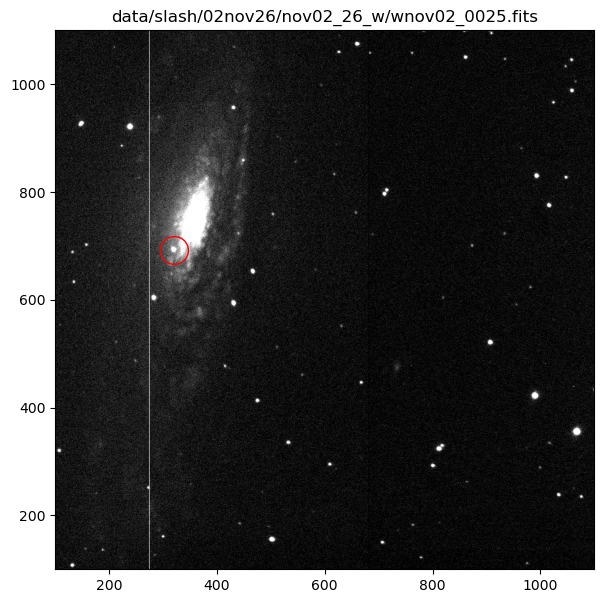

In [39]:
### Let's look at one image and mark where the supernova is
data = fits.getdata(B_files[0])
h = fits.getheader(B_files[0])
x, y = WCS(h).world_to_pixel(sn26aaiv)

plt.figure(figsize=(7, 7))
plt.imshow(data, origin="lower", cmap="gray", vmin=10, vmax=50)
plt.plot(x, y, "o", ms=20, mfc="none", color="red")
plt.title(B_files[0])
plt.xlim(100, 1100)
plt.ylim(100, 1100)
plt.show()


### 2. Now let us start the data processing!

##### 1. Bias reduction

In [40]:
### Let's find our bias files first
### Bias files are called "zero" in the header (0 second exposures)
bias_files = []
for f in all_files:
    if fits.getheader(f)["IMAGETYP"] == "zero":
        bias_files.append(f)

print(len(bias_files), "bias files")
bias_files


12 bias files


['data/slash/03nov26/nov03_26/nov03_0001.fits',
 'data/slash/03nov26/nov03_26/nov03_0002.fits',
 'data/slash/03nov26/nov03_26/nov03_0003.fits',
 'data/slash/03nov26/nov03_26/nov03_0004.fits',
 'data/slash/03nov26/nov03_26/nov03_0005.fits',
 'data/slash/03nov26/nov03_26/nov03_0006.fits',
 'data/slash/03nov26/nov03_26/nov03_0007.fits',
 'data/slash/03nov26/nov03_26/nov03_0008.fits',
 'data/slash/03nov26/nov03_26/nov03_0009.fits',
 'data/slash/03nov26/nov03_26/nov03_0010.fits',
 'data/slash/03nov26/nov03_26/nov03_0011.fits',
 'data/slash/03nov26/nov03_26/nov03_0012.fits']

In [41]:
### combining them into a master bias (same as the SN lab)
bias_frames = []
for f in bias_files:
    bias_frames.append(fits.getdata(f))
bias_frames = np.array(bias_frames)
print(bias_frames.shape)

### Median combine them
master_bias = np.median(bias_frames, axis=0)
print("master bias median:", np.median(master_bias))

(12, 1365, 1365)
master bias median: 2.592987


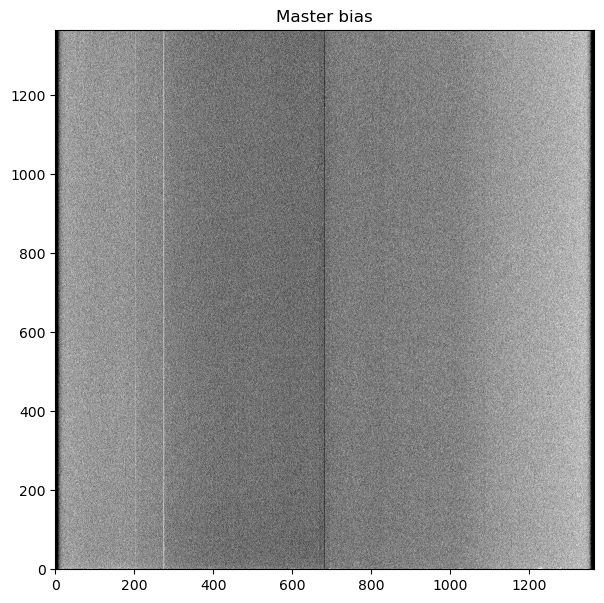

In [42]:
### See the master bias
plt.figure(figsize=(7, 7))
plt.imshow(master_bias, origin="lower", cmap="gray", vmin=0, vmax=5)
plt.title("Master bias")
plt.show()

##### 2. Dark current

In [43]:
### Dark files from the header (skip wdon.fits)
dark_files = []
for f in all_files:
    if fits.getheader(f)["IMAGETYP"] == "dark" and "wdon" not in f:
        dark_files.append(f)

print(len(dark_files), "dark files")
dark_files

5 dark files


['data/slash/02nov26/nov02_26/nov02_0002.fits',
 'data/slash/02nov26/nov02_26/nov02_0003.fits',
 'data/slash/02nov26/nov02_26/nov02_0004.fits',
 'data/slash/02nov26/nov02_26/nov02_0005.fits',
 'data/slash/02nov26/nov02_26/nov02_0006.fits']

In [44]:
### Read all the dark frames into one array
dark_frames = []
for f in dark_files:
    dark_frames.append(fits.getdata(f))
dark_frames = np.array(dark_frames)
print(dark_frames.shape)

### Median combine them
master_dark = np.median(dark_frames, axis=0)

### A dark also has the bias, so take it out,
### then divide by the exposure time to get counts per second
### similar steps to the lab notebooks, check them out
dark_exptime = fits.getheader(dark_files[0])["EXPTIME"]
dark_rate = (master_dark - master_bias) / dark_exptime

print("dark exposure time:", dark_exptime, "s")
print("dark current:", np.median(dark_rate), "counts/pixel/s")

(5, 1365, 1365)
dark exposure time: 90.0 s
dark current: 0.027823893 counts/pixel/s


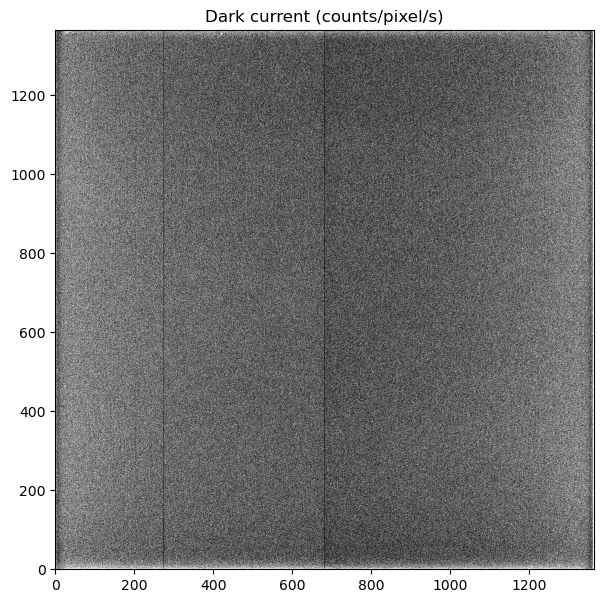

In [45]:
### See the dark current
plt.figure(figsize=(7, 7))
plt.imshow(dark_rate, origin="lower", cmap="gray", vmin=0, vmax=0.07)
plt.title("Dark current (counts/pixel/s)")
plt.show()


##### 3. Flats

In [46]:
### Flat files from the header, split by filter
flat_U_files, flat_B_files, flat_R_files = [], [], []
for f in all_files:
    h = fits.getheader(f)
    if h["IMAGETYP"] == "flat":
        if h["FILTER"] == "Bessell-U":
            flat_U_files.append(f)
        elif h["FILTER"] == "Harris-B" and h["EXPTIME"] == 30:
            flat_B_files.append(f)
        elif h["FILTER"] == "Harris-R":
            flat_R_files.append(f)

print(len(flat_U_files), "U flats,", len(flat_B_files), "B flats,", len(flat_R_files), "R flats")

### *** No V flats in November, so I'll borrow the Oct 25 ones (rflat3 folder)
oct25_files = sorted(glob.glob("data/slash/rflat3/*.fits"))

flat_V_files = []
for f in oct25_files:
    h = fits.getheader(f)
    if h["IMAGETYP"] == "flat" and h["FILTER"] == "Harris-V" and "test" not in f:
        flat_V_files.append(f)

print(len(flat_V_files), "V flats")

11 U flats, 11 B flats, 11 R flats
28 V flats


In [47]:
### function to make flats
def make_flat(flat_files):
    flat_frames = []
    for f in flat_files:
        data = fits.getdata(f)
        exptime = fits.getheader(f)["EXPTIME"]
        ### take out the bias and dark
        clean = data - master_bias - dark_rate * exptime
        ### normalize
        flat_frames.append(clean / np.median(clean))
    flat_frames = np.array(flat_frames)

    ### median combine
    master_flat = np.median(flat_frames, axis=0)

    ### column 682 is empty (it's where the two halves of the detector meet),
    ### set it to 1 so we never divide by zero
    master_flat[master_flat == 0] = 1
    return master_flat

In [48]:
flat_U = make_flat(flat_U_files)
flat_B = make_flat(flat_B_files)
flat_V = make_flat(flat_V_files)
flat_R = make_flat(flat_R_files)

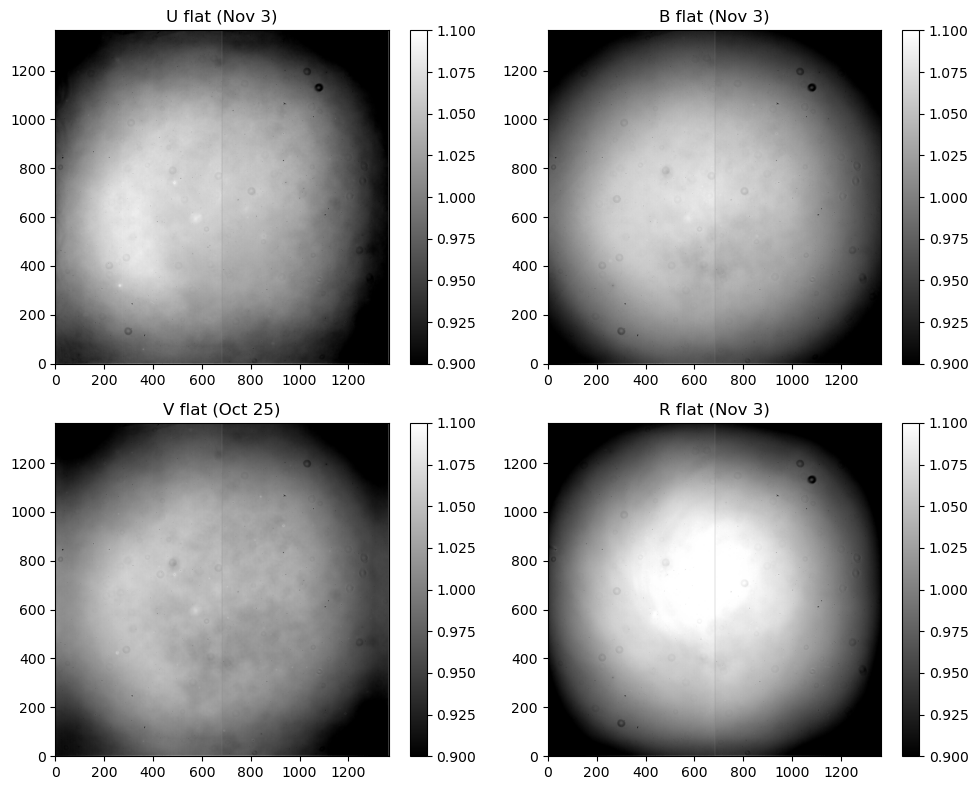

In [49]:
### display them
### since there'll be 4 plots, use matplotlib's numbering
### 22 means 2 by 2, and 221 means first on the top left, and so on
plt.figure(figsize=(10, 8))

plt.subplot(221)
plt.imshow(flat_U, origin="lower", cmap="gray", vmin=0.9, vmax=1.1)
plt.title("U flat (Nov 3)"); plt.colorbar()

plt.subplot(222)
plt.imshow(flat_B, origin="lower", cmap="gray", vmin=0.9, vmax=1.1)
plt.title("B flat (Nov 3)"); plt.colorbar()

plt.subplot(223)
plt.imshow(flat_V, origin="lower", cmap="gray", vmin=0.9, vmax=1.1)
plt.title("V flat (Oct 25)"); plt.colorbar()

plt.subplot(224)
plt.imshow(flat_R, origin="lower", cmap="gray", vmin=0.9, vmax=1.1)
plt.title("R flat (Nov 3)"); plt.colorbar()

plt.tight_layout()
plt.show()


##### 4. Applying the bias, dark, and flat
$$ \rm Science_{reduced}= \frac{Science - Bias - Dark Rate \times t_{exp}}{Flat}

In [50]:
### Folder for the reduced images
out_dir = "data/reduced"
os.makedirs(out_dir, exist_ok=True)

### function to apply the equation above
def reduce_files(sci_files, master_flat):
    out_files = []
    for f in sci_files:
        data = fits.getdata(f)
        header = fits.getheader(f)
        exptime = header["EXPTIME"]

        ### bias, dark (scaled to this exposure), and flat
        reduced = (data - master_bias - dark_rate * exptime) / master_flat

        ### save with the original header, so the WCS is kept
        out = os.path.join(out_dir, os.path.basename(f).replace(".fits", "_red.fits"))
        fits.writeto(out, reduced, header, overwrite=True)
        out_files.append(out)
    return out_files

In [51]:
U_red = reduce_files(U_files, flat_U)
B_red = reduce_files(B_files, flat_B)
V_red = reduce_files(V_files, flat_V)
R_red = reduce_files(R_files, flat_R)

print("U:", len(U_red), " B:", len(B_red), " V:", len(V_red), " R:", len(R_red))

U: 6  B: 7  V: 6  R: 10


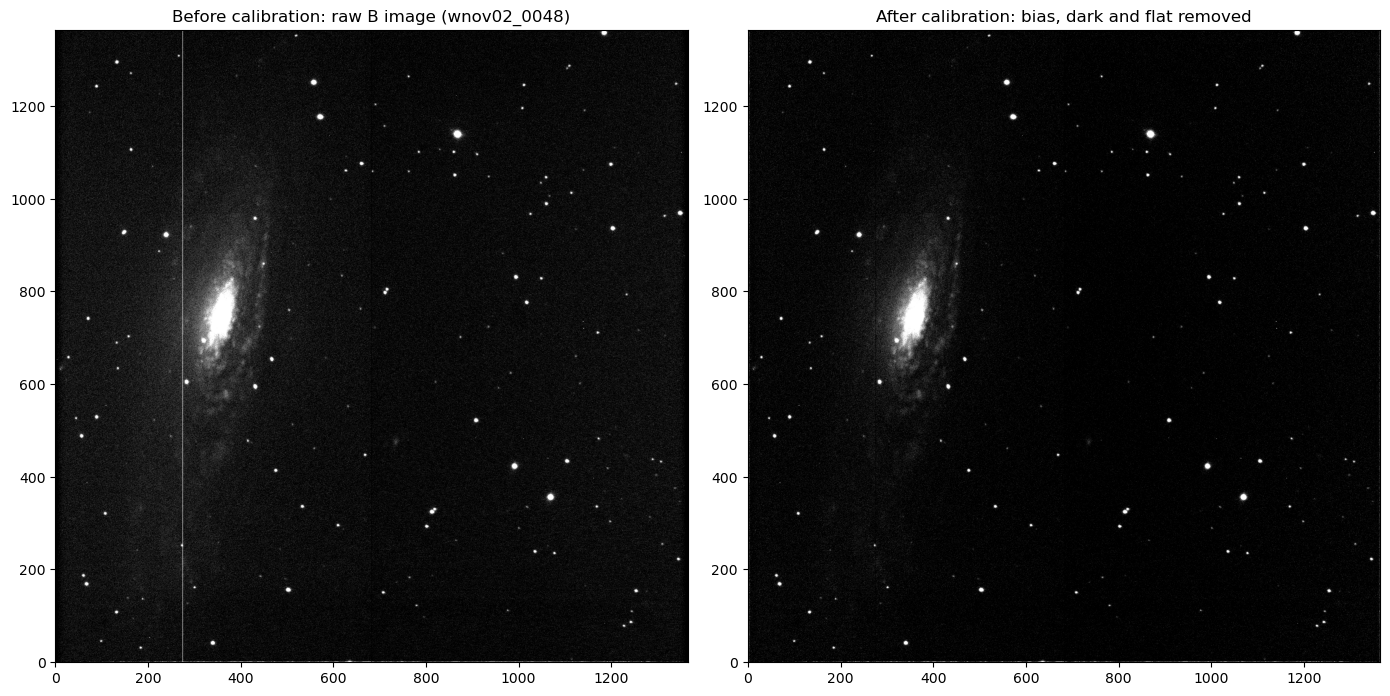

In [52]:
### Let's see the before and after!
before = fits.getdata(B_files[0])
after = fits.getdata(B_red[0])

plt.figure(figsize=(14, 7))

plt.subplot(121)
plt.imshow(before, origin="lower", cmap="gray", vmin=10, vmax=50)
plt.title("Before calibration: raw B image (wnov02_0048)")

plt.subplot(122)
plt.imshow(after, origin="lower", cmap="gray", vmin=10, vmax=50)
plt.title("After calibration: bias, dark and flat removed")

plt.tight_layout()
plt.show()


### 3. Aperture photometry

In [53]:
### since we have the RA and DEC, center the aperture there
### Let it be a variable though, I may want to change it to another sn
### docstrings generated and written by a vscode extension of mine, they're good!
def counts_per_sec(f, coord=sn26aaiv, delta_x=0, delta_y=0, r=8, r_in=15, r_out=20):
    """
    Measure the brightness of a source in counts per second.

    Args:
        f (str): Path to a reduced FITS image.
        coord (SkyCoord): Sky position of the source. Defaults to sn26aaiv.
        delta_x (float): Shift the aperture left/right by hand, in pixels. Defaults to 0.
        delta_y (float): Shift the aperture up/down by hand, in pixels. Defaults to 0.
        r (float): Aperture radius in pixels. Defaults to 8.
        r_in (float): Inner radius of the sky annulus in pixels. Defaults to 15.
        r_out (float): Outer radius of the sky annulus in pixels. Defaults to 20.

    Returns:
        tuple: (flux, flux_err), the sky-subtracted counts per second and its error.
    """
    data = fits.getdata(f)
    h = fits.getheader(f)
    x, y = WCS(h).world_to_pixel(coord)
    x = x + delta_x
    y = y + delta_y
    ap = CircularAperture((x, y), r=r)
    an = CircularAnnulus((x, y), r_in=r_in, r_out=r_out)

    ### sky level and scatter from the annulus (sigma clipped, like the a5 lab)
    an_stats = ApertureStats(data, an, sigma_clip=SigmaClip(sigma=3))
    sky = an_stats.median
    flux = aperture_photometry(data, ap)["aperture_sum"][0] - sky * ap.area
    flux_err = np.sqrt(ap.area) * an_stats.std
    return flux / h["EXPTIME"], flux_err / h["EXPTIME"]



### show the aperture
def show_aperture(f, coord=sn26aaiv, delta_x=0, delta_y=0, r=8, r_in=15, r_out=20,
                  size=40, vmin=120, vmax=1000):
    """
    Plot a zoomed-in view of a source with its aperture and sky annulus.

    Args:
        f (str): Path to a reduced FITS image.
        coord (SkyCoord): Sky position of the source. Defaults to sn26aaiv.
        delta_x (float): Shift the aperture left/right by hand, in pixels. Defaults to 0.
        delta_y (float): Shift the aperture up/down by hand, in pixels. Defaults to 0.
        r (float): Aperture radius in pixels. Defaults to 8.
        r_in (float): Inner radius of the sky annulus in pixels. Defaults to 15.
        r_out (float): Outer radius of the sky annulus in pixels. Defaults to 20.
        size (int): Half-width of the zoomed-in view in pixels. Defaults to 40.
        vmin (float): Lower limit of the color scale. Defaults to 120.
        vmax (float): Upper limit of the color scale. Defaults to 1000.
    """
    data = fits.getdata(f)
    h = fits.getheader(f)
    x, y = WCS(h).world_to_pixel(coord)
    ### shift the position by hand (in pixels)
    x = x + delta_x
    y = y + delta_y
    ap = CircularAperture((x, y), r=r)
    an = CircularAnnulus((x, y), r_in=r_in, r_out=r_out)

    plt.figure(figsize=(6, 6))
    plt.imshow(data, origin="lower", cmap="gray", vmin=vmin, vmax=vmax)
    ap.plot(color="red", lw=2, label="Aperture")
    an.plot(color="yellow", lw=2, label="Sky annulus")
    plt.xlim(x - size, x + size)
    plt.ylim(y - size, y + size)
    plt.title(f.split("/")[-1])
    plt.legend()
    plt.show()

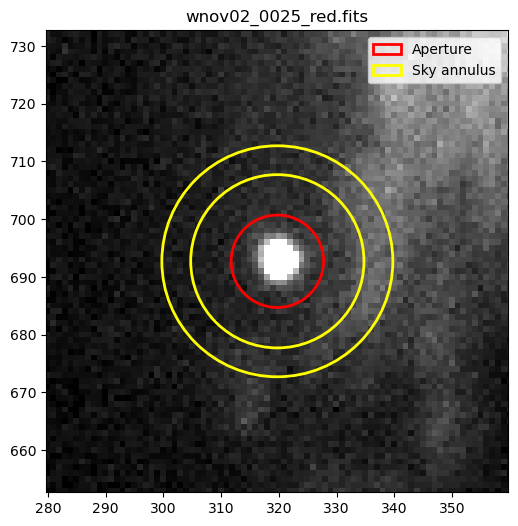

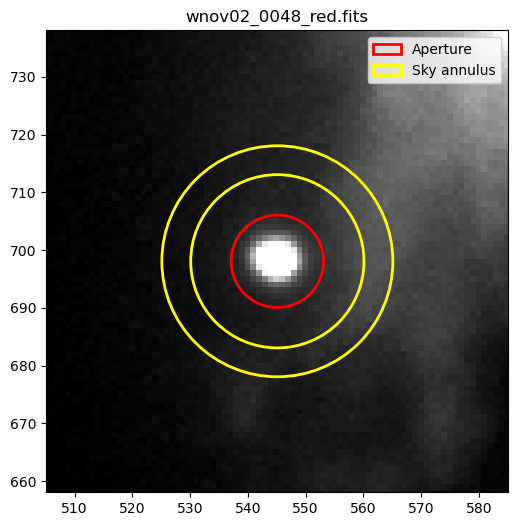

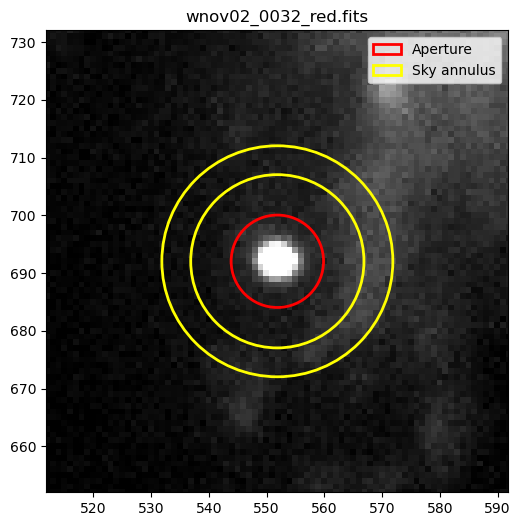

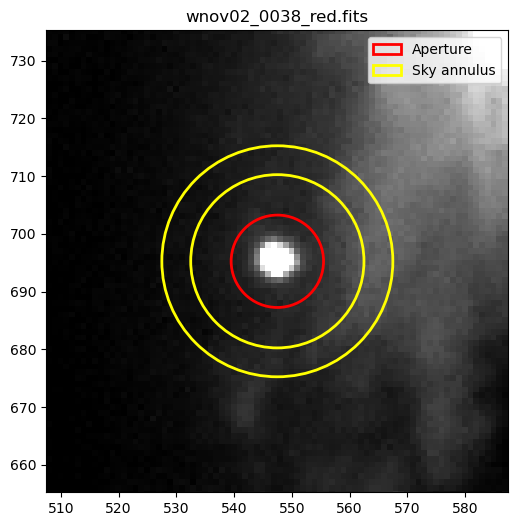

In [54]:
### I manually set these
show_aperture(B_red[0], vmin=10, vmax=100, delta_y = 1)
show_aperture(V_red[0], vmin=120, vmax=1000, delta_x=2)    
show_aperture(U_red[0], vmin=20, vmax=200, delta_x=2)
show_aperture(R_red[0], vmin=120, vmax=900, delta_x=2)


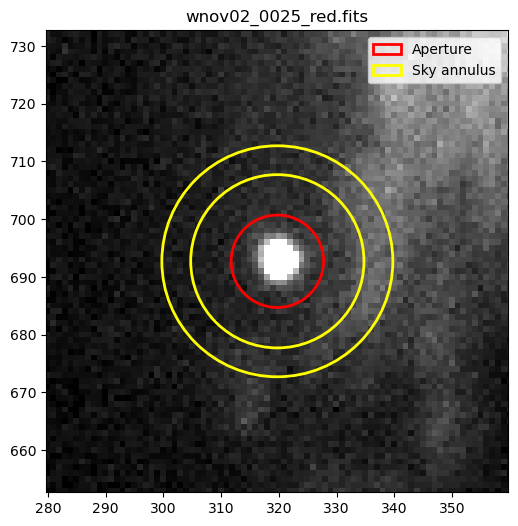

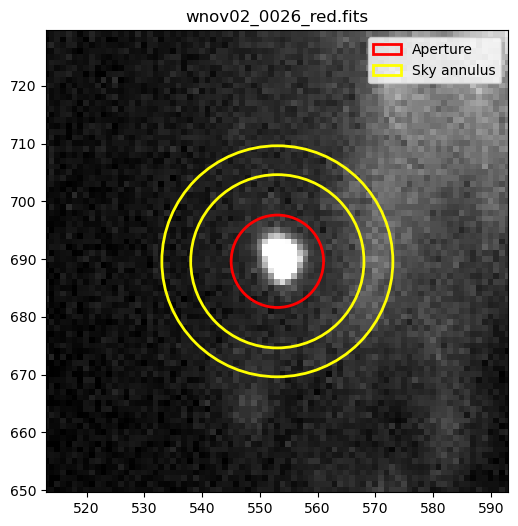

In [55]:
### To check if the images are off from one another or not
show_aperture(B_red[0], vmin=10, vmax=100, delta_y = 1)
show_aperture(B_red[1], vmin=10, vmax=100, delta_x=2)    

In [56]:
def curve_of_growth(f, coord=sn26aaiv, delta_x=0, delta_y=0, r_in=15, r_out=20):
    """
    Measure the signal-to-noise and the light captured for a range of aperture radii.

    Args:
        f (str): Path to a reduced FITS image.
        coord (SkyCoord): Sky position of the source. Defaults to sn26aaiv.
        delta_x (float): Shift the aperture left/right by hand, in pixels. Defaults to 0.
        delta_y (float): Shift the aperture up/down by hand, in pixels. Defaults to 0.
        r_in (float): Inner radius of the sky annulus in pixels. Defaults to 15.
        r_out (float): Outer radius of the sky annulus in pixels. Defaults to 20.

    Returns:
        tuple: (radii, snrs, fractions), the radii tried, the signal-to-noise at each
            radius, and the fraction of the light captured at each radius.
    """
    data = fits.getdata(f)
    h = fits.getheader(f)
    x, y = WCS(h).world_to_pixel(coord)
    x = x + delta_x
    y = y + delta_y

    ### sky level and scatter from the annulus
    ### sigma clip it, like I had done in the photometry lab
    an = CircularAnnulus((x, y), r_in=r_in, r_out=r_out)
    an_stats = ApertureStats(data, an, sigma_clip=SigmaClip(sigma=3))
    sky = an_stats.median
    sky_std = an_stats.std

    radii = np.arange(1, 13, 0.5)
    fluxes = []
    snrs = []
    ### loop over these radii to find the SNR and the percentage of light 
    for r in radii:
        ap = CircularAperture((x, y), r=r)
        flux = aperture_photometry(data, ap)["aperture_sum"][0] - sky * ap.area
        flux_err = np.sqrt(ap.area) * sky_std
        fluxes.append(flux)
        snrs.append(flux / flux_err)

    fluxes = np.array(fluxes)
    fractions = fluxes / fluxes[-1]
    return radii, np.array(snrs), fractions


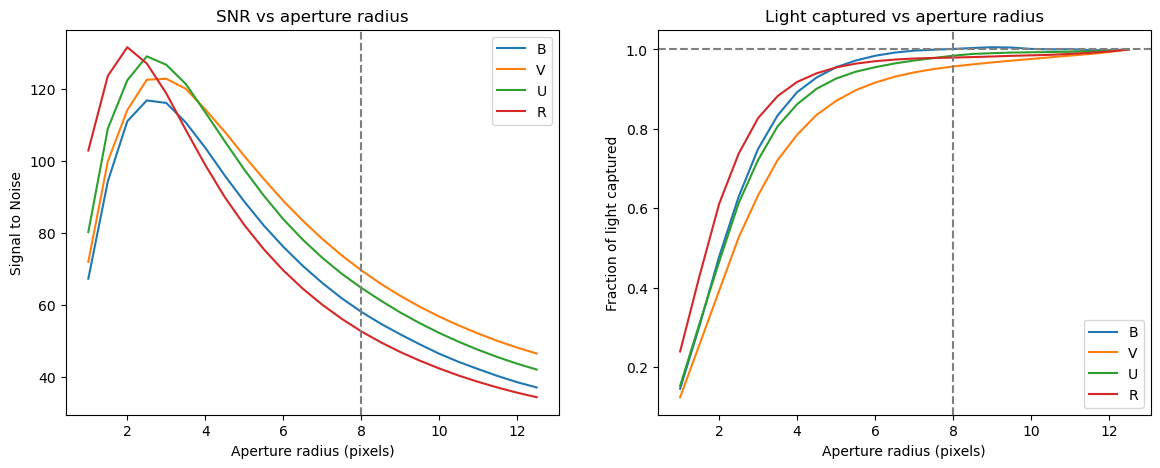

In [57]:
### Curve of growth for the first image of each filter (with my manual shifts)
radii, snr_B, frac_B = curve_of_growth(B_red[0], delta_y=1)
radii, snr_V, frac_V = curve_of_growth(V_red[0], delta_x=2)
radii, snr_U, frac_U = curve_of_growth(U_red[0], delta_x=2)
radii, snr_R, frac_R = curve_of_growth(R_red[0], delta_x=2)

### plot them on one plot
plt.figure(figsize=(14, 5))

### Again, 121 stands for a 1 by 2's left block
plt.subplot(121)
plt.plot(radii, snr_B, label="B")
plt.plot(radii, snr_V, label="V")
plt.plot(radii, snr_U, label="U")
plt.plot(radii, snr_R, label="R")
plt.axvline(8, color="gray", linestyle="--")
plt.xlabel("Aperture radius (pixels)")
plt.ylabel("Signal to Noise")
plt.title("SNR vs aperture radius")
plt.legend()

plt.subplot(122)
plt.plot(radii, frac_B, label="B")
plt.plot(radii, frac_V, label="V")
plt.plot(radii, frac_U, label="U")
plt.plot(radii, frac_R, label="R")
plt.axvline(8, color="gray", linestyle="--")
plt.axhline(1, color="gray", linestyle="--")
plt.xlabel("Aperture radius (pixels)")
plt.ylabel("Fraction of light captured")
plt.title("Light captured vs aperture radius")
plt.legend()
plt.show()


I will go with a radius of 8. This accounts for the small shifts that I've done. I would think that there is some offset between the filters, and I currently do not want to manually find what the best centering for each filter is. With choosing an aperture radius of 8 pixels, it would account for those shifts since no centering shift will be more than a few pixels. So although we get slightly worse SNR, I think it's a good enough choice. I might write something more sophisticated later, but for now, this is good enough. 

##### Now let's measure every image

In [58]:
### measures a sourcec in every image of a list, uses the last functions
def measure_all(files, coord=sn26aaiv, delta_x=0, delta_y=0, r=8, r_in=15, r_out=20):
    mjds, fluxes, errors = [], [], []
    for f in files:
        h = fits.getheader(f)
        flux, err = counts_per_sec(f, coord, delta_x, delta_y, r, r_in, r_out)
        ### time from DATE-OBS + UT (not MJD-OBS, that one is only the date)
        mjds.append(Time(h["DATE-OBS"] + "T" + h["UT"]).mjd)
        fluxes.append(flux)
        errors.append(err)
    return np.array(mjds), np.array(fluxes), np.array(errors)


In [59]:
### run the function on all filters
### 0025 was taken at a different telescope pointing from the other B images, so leave it out
mjd_B, flux_B, err_B = measure_all(B_red[1:], delta_x=2)
mjd_V, flux_V, err_V = measure_all(V_red, delta_x=2)
mjd_U, flux_U, err_U = measure_all(U_red, delta_x=2)
mjd_R, flux_R, err_R = measure_all(R_red, delta_x=2)

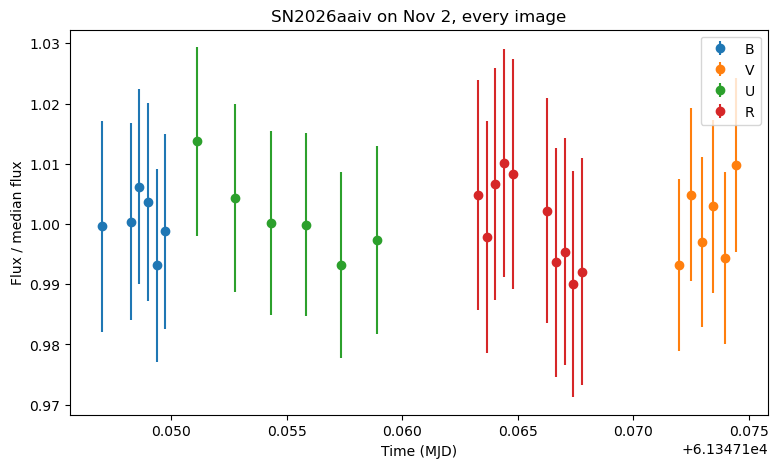

In [60]:
plt.figure(figsize=(9, 5))
plt.errorbar(mjd_B, flux_B / np.median(flux_B), yerr=err_B / np.median(flux_B), fmt="o", label="B")
plt.errorbar(mjd_V, flux_V / np.median(flux_V), yerr=err_V / np.median(flux_V), fmt="o", label="V")
plt.errorbar(mjd_U, flux_U / np.median(flux_U), yerr=err_U / np.median(flux_U), fmt="o", label="U")
plt.errorbar(mjd_R, flux_R / np.median(flux_R), yerr=err_R / np.median(flux_R), fmt="o", label="R")
plt.xlabel("Time (MJD)")
plt.ylabel("Flux / median flux")
plt.title("SN2026aaiv on Nov 2, every image")
plt.legend()
plt.savefig("figs/nov2_median_fluxes.jpg")
plt.show()


In [61]:
### Put all filters together and save them
### join the arrays back to back together and save
mjd = np.concatenate([mjd_U, mjd_B, mjd_V, mjd_R])
flux = np.concatenate([flux_U, flux_B, flux_V, flux_R])
err = np.concatenate([err_U, err_B, err_V, err_R])

### make a filter column too
filt = np.array(["U"] * len(mjd_U) + ["B"] * len(mjd_B) + ["V"] * len(mjd_V) + ["R"] * len(mjd_R))

### First line: when and by who. Second line: column names
saved = "# Made on " + str(datetime.now()) + " by Arshia Akhtarkavan"

### Save as columns with a header line
np.savetxt("data/text_files/nov2_counts.txt", np.column_stack([mjd, flux, err, filt]), fmt="%s",
           header="mjd flux err filter", comments="")


In [62]:
print("Run on", datetime.now(), "by Arshia")

Run on 2026-11-20 13:37:39.753926 by Arshia
